# Curvilinear grids: waves under topography

On a `Grid` the nodes form a box, so a surface that is not flat, such as topography, can only be approximated by a staircase of cells, and the waves that reflect off it pick up the error of the staircase. A `CurvilinearGrid` bends the grid instead, so that the surface is a row of nodes.

The equations do not change. A `CurvilinearGrid` is used as a `Grid`: the acoustic wave equation is still `m*u.dt2 - u.laplace`, `u.dx` is still the derivative along $x$, and sources and receivers are still placed at their physical coordinates. Devito applies the map when the derivatives are evaluated.

This tutorial simulates an acoustic shot over a hill with a free surface that follows the topography. Along the way it shows how a `CurvilinearGrid` is defined, how derivatives, sparse functions and models work on it, how the free surface and the adjoint are written, and how accurate the result is against an analytic solution.

**Notation.** $x$ and $z$ are the physical coordinates, in metres, with $z$ the depth, positive down as everywhere in Devito. The grid is still indexed by integer nodes along each axis, as a `Grid`; the uniformly spaced coordinates of these nodes are the *computational* coordinates $\xi$ (lateral) and $\eta$ (vertical), which the grid `Dimension`s index. A *map* places each computational node $(\xi, \eta)$ at a physical position $(x, z)$. In 2D Devito names the vertical `Dimension` `y`, so below `y` is the vertical grid `Dimension` and `u.dy` the vertical derivative.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from devito import (CurvilinearGrid, CurvilinearMap, Eq, Function, Grid, Inc, MeshMap,
                    Operator, SparseTimeFunction, TensorTimeFunction,
                    TerrainFollowing, TimeFunction, VectorTimeFunction, diag, div, grad,
                    initialize_function, resample, solve)
from examples.seismic import AcquisitionGeometry, SeismicModel
from examples.seismic.model import FreeSurfaceRows, RowsDomain
from examples.seismic.acoustic import AcousticWaveSolver

## 1. The grid

### The topography

The topography is a hill 150 m high, centred at $x = 1.5$ km on a 3 km line, given as topography usually is: as an elevation above a datum, positive up.

In [2]:
def elevation(x):
    return 150.*np.exp(-((x - 1500.)/400.)**2)

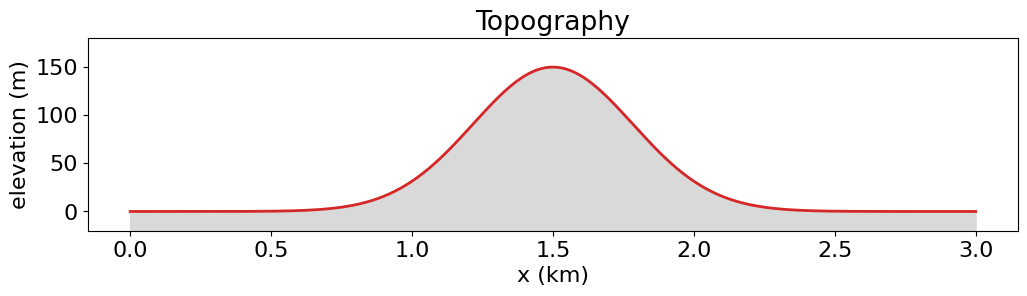

In [3]:
# NBVAL_IGNORE_OUTPUT
x_line = np.linspace(0., 3000., 301)
fig, ax = plt.subplots(figsize=(12, 2.5))
ax.fill_between(x_line/1000, elevation(x_line), -20., color='0.85')
ax.plot(x_line/1000, elevation(x_line), 'C3', lw=2)
ax.set_xlabel('x (km)')
ax.set_ylabel('elevation (m)')
ax.set_ylim(-20., 180.)
ax.set_title('Topography')
plt.show()

### The terrain-following map

`TerrainFollowing` keeps the lateral coordinate, $x = \xi$, and spreads the nodes of each column evenly between the surface, at depth $s(x)$, and a flat bottom at depth $b$:

$$
z(\xi, \eta) = s(\xi) + \eta\,\frac{b - s(\xi)}{b}.
$$

The row at computational depth $\eta = 0$ is the surface, and the last row of the grid, at $\eta = b$, is the flat bottom $z = b$. The relief of the surface fades out linearly with depth, and over a flat surface at $s = 0$ the map is the identity.

Depths are positive down, so the surface is the negative of the elevation, `surface=-elevation`. It can be a function of $x$, as here, or an array with one value per lateral node.

### Rows above the surface

The free surface (section 4) mirrors the wavefield into rows *above* the surface, which must therefore be part of the grid. They are added by extending the grid upwards with a negative vertical `origin`: the map places them at $\eta < 0$, above the surface. The mirror must cover every row the stencils read above the surface: the Laplacian of space order 8 reads 4 rows, and the staggered pairs of the variable-density operator of section 7 read 8, so the grid gets 8 rows above the surface.

The grid below has 301 by 151 nodes from the surface down, over 3000 m by 1500 m, so its spacing is 10 m, plus the 8 rows above. Apart from `mapping`, the arguments are those of a `Grid`.

In [4]:
above = 8  # rows above the surface
mapping = TerrainFollowing(surface=lambda x: -elevation(x))
grid = CurvilinearGrid(shape=(301, 151 + above), extent=(3000., 1500. + 10.*above),
                       origin=(0., -10.*above), mapping=mapping)
x, y = grid.dimensions

print(f'Dimensions {grid.dimensions}, shape {grid.shape}, '
      f'spacing {float(grid.spacing[0]):.0f} m')

Dimensions (x, y), shape (301, 159), spacing 10 m


`grid.coordinates` holds the physical coordinates $x$ and $z$ of every node, as two `Function`s. Drawn in physical space, every fifth grid line shows the columns stretched between the hill and the flat bottom: the rows follow the hill near the surface and flatten with depth. The plots of this notebook show the grid from the surface down.

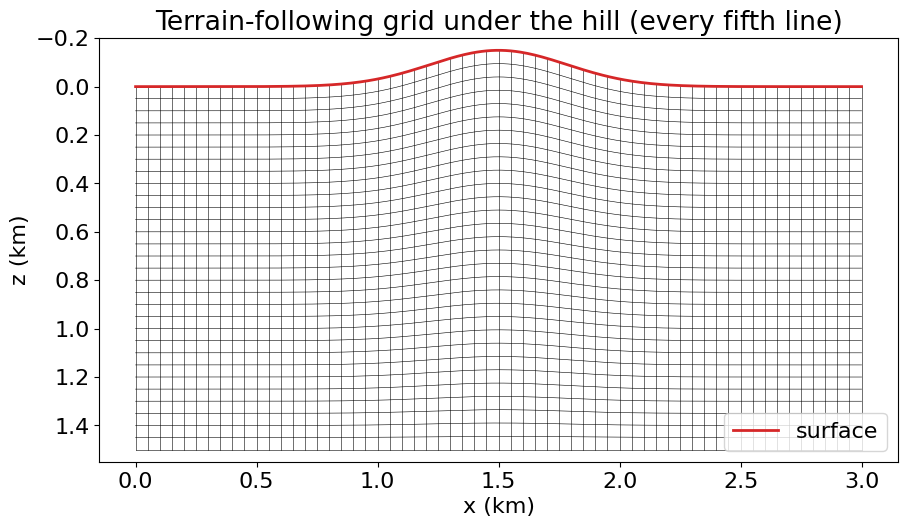

In [5]:
# NBVAL_IGNORE_OUTPUT
below = (slice(None), slice(above, None))  # from the surface down
x_coord, z_coord = (c.data[below]/1000 for c in grid.coordinates)


def plot_grid_lines(ax, step=5):
    ax.plot(x_coord[::step, :].T, z_coord[::step, :].T, 'k', lw=.4)
    ax.plot(x_coord[:, ::step], z_coord[:, ::step], 'k', lw=.4)


fig, ax = plt.subplots(figsize=(12, 5.5))
plot_grid_lines(ax)
ax.plot(x_coord[:, 0], z_coord[:, 0], 'C3', lw=2, label='surface')
ax.set_xlabel('x (km)')
ax.set_ylabel('z (km)')
ax.set_ylim(1.55, -.2)
ax.set_aspect('equal')
ax.legend(loc='lower right')
ax.set_title('Terrain-following grid under the hill (every fifth line)')
plt.show()

Near the surface, the rows above it, which hold the mirror of the wavefield (section 4), follow the hill as well. On the flank of the hill the grid lines are vertical and the rows sloped, so the cells are sheared:

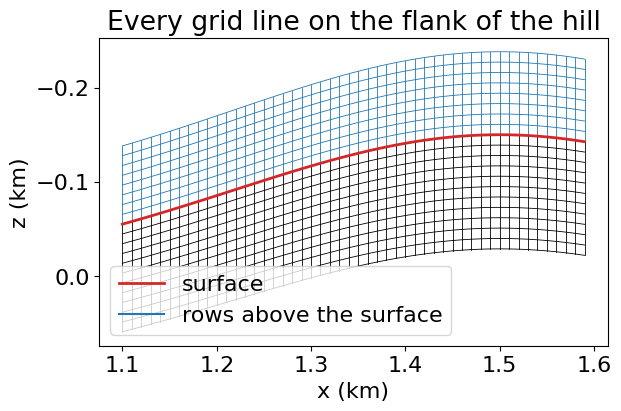

In [6]:
# NBVAL_IGNORE_OUTPUT
x_all, z_all = (c.data/1000 for c in grid.coordinates)
fig, ax = plt.subplots(figsize=(12, 4))
window = slice(110, 160)
ax.plot(x_all[window, :above + 1].T, z_all[window, :above + 1].T, 'C0', lw=.6)
ax.plot(x_all[window, :above + 1], z_all[window, :above + 1], 'C0', lw=.6)
ax.plot(x_all[window, above:above + 12].T, z_all[window, above:above + 12].T, 'k', lw=.6)
ax.plot(x_all[window, above:above + 12], z_all[window, above:above + 12], 'k', lw=.6)
ax.plot(x_all[window, above], z_all[window, above], 'C3', lw=2, label='surface')
ax.plot([], [], 'C0', label='rows above the surface')
ax.set_xlabel('x (km)')
ax.set_ylabel('z (km)')
ax.invert_yaxis()
ax.set_aspect('equal')
ax.legend(loc='lower left')
ax.set_title('Every grid line on the flank of the hill')
plt.show()

## 2. Derivatives on the grid

### Metric terms and Jacobian

Finite differences are taken along the grid, with respect to $\xi$ and $\eta$, while the wave equation needs derivatives with respect to $x$ and $z$. The chain rule connects them through the *metric terms*, the derivatives of the computational coordinates with respect to the physical ones,

$$
\frac{\partial}{\partial x} = \frac{\partial \xi}{\partial x}\frac{\partial}{\partial \xi} + \frac{\partial \eta}{\partial x}\frac{\partial}{\partial \eta},
\qquad
\frac{\partial}{\partial z} = \frac{\partial \xi}{\partial z}\frac{\partial}{\partial \xi} + \frac{\partial \eta}{\partial z}\frac{\partial}{\partial \eta}.
$$

The grid also provides the *Jacobian* $J = \det\left(\partial(x, z)/\partial(\xi, \eta)\right)$, the area of a physical cell over that of a computational cell. The grid computes them by finite differences of the map; for the terrain-following map they are

$$
\frac{\partial \xi}{\partial x} = 1, \qquad
\frac{\partial \xi}{\partial z} = 0, \qquad
\frac{\partial \eta}{\partial x} = s'(x)\,\frac{\eta - b}{b - s(x)}, \qquad
\frac{\partial \eta}{\partial z} = \frac{b}{b - s(x)}, \qquad
J = \frac{b - s(x)}{b}.
$$

`grid.metrics` is a dictionary keyed by (physical `Dimension`, computational `Dimension`). Entries that vary in space are `Function`s named after the computational coordinate and the physical axis, so `eta_x` is $\partial\eta/\partial x$; entries that are the same everywhere on the grid are numbers. `grid.jacobian` is $J$.

In [7]:
grid.metrics

{(x, x): 1, (x, y): eta_x(x, y), (y, x): 0, (y, y): eta_y(x, y)}

The slope term $\partial\eta/\partial x$ is largest on the flanks of the hill and fades with depth, and $J$ is above one under the hill, where each column spans a longer physical height.

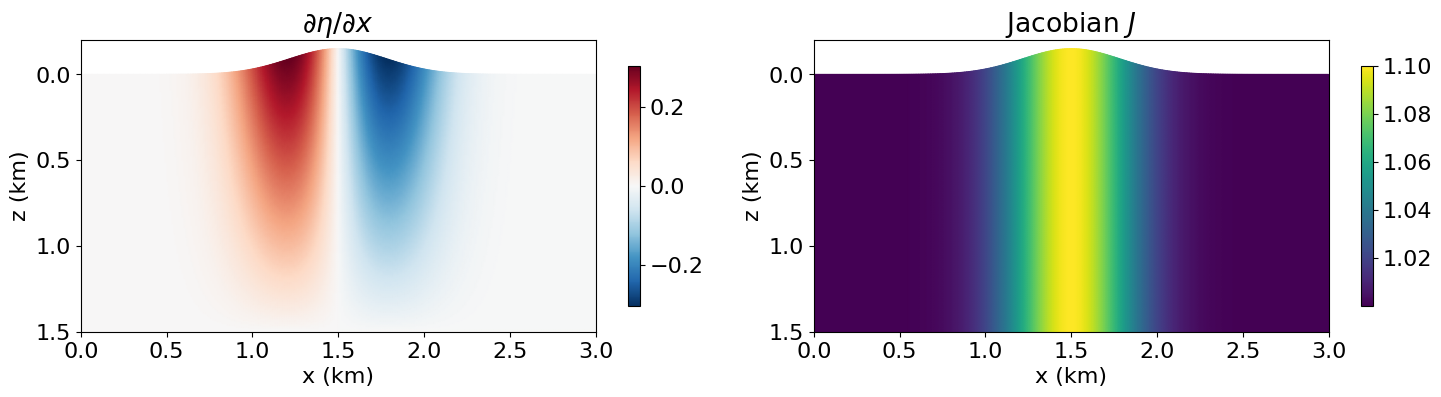

In [8]:
# NBVAL_IGNORE_OUTPUT
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
panels = [(grid.metrics[(x, y)].data[below], r'$\partial\eta/\partial x$', 'RdBu_r'),
          (grid.jacobian.data[below], 'Jacobian $J$', 'viridis')]
for ax, (values, title, cmap) in zip(axes, panels, strict=True):
    image = ax.pcolormesh(x_coord, z_coord, values, cmap=cmap, shading='gouraud')
    ax.set_ylim(1.5, -.2)
    ax.set_aspect('equal')
    ax.set_xlabel('x (km)')
    ax.set_ylabel('z (km)')
    ax.set_title(title)
    fig.colorbar(image, ax=ax, shrink=.6)
plt.tight_layout()
plt.show()

### Physical derivatives

On a `CurvilinearGrid`, `u.dx` and `u.dy` are the derivatives with respect to the physical $x$ and $z$: Devito applies the chain rule when the derivative is evaluated. It shows in the stencil of `u.dx` of space order 2: the difference along the grid $x$ axis that `u.dx` is on a `Grid`, one-sided as Devito takes a first derivative of order 2, plus the centered difference along the grid $y$ axis times the metric term `eta_x`, $\partial\eta/\partial x$, at the node:

In [9]:
u = Function(name='u', grid=grid, space_order=2)
u.dx.evaluate

-u(x, y)/h_x + u(x + h_x, y)/h_x + (-0.5*u(x, y - h_y)/h_y + 0.5*u(x, y + h_y)/h_y)*eta_x(x, y)

The derivative along the grid axis, ignoring the map, is written `u.dx(computational=True)`.

A simple check of the physical derivatives is to differentiate the physical depth $z$ itself: $\partial z/\partial x$ must vanish and $\partial z/\partial z$ must be one everywhere, although $z$ varies along the grid rows.

In [10]:
# NBVAL_IGNORE_OUTPUT
depth = Function(name='depth', grid=grid, space_order=8)
dzdx = Function(name='dzdx', grid=grid, space_order=8)
dzdz = Function(name='dzdz', grid=grid, space_order=8)
depth.data[:] = grid.coordinates[1].data

summary = Operator([Eq(dzdx, depth.dx), Eq(dzdz, depth.dy)]).apply()

NUMA domain count autodetection failed, assuming 1


Operator `Kernel` ran in 0.01 s


In [11]:
interior = (slice(4, -4), slice(4, -4))
print(f'max |dz/dx|     = {np.abs(dzdx.data[interior]).max():.1e}')
print(f'max |dz/dz - 1| = {np.abs(dzdz.data[interior] - 1).max():.1e}')

max |dz/dx|     = 1.1e-05
max |dz/dz - 1| = 1.0e-05


### Accuracy of the Laplacian

The Laplacian of a smooth field shows the accuracy of the physical derivatives on the curved grid. For $u = \sin(kx)\cos(kz)$ with a wavelength of 300 m, $\nabla^2 u = -2k^2 u$. On a double-precision copy of the hill grid, `u.laplace` gives it to about $10^{-8}$ of its largest value, all over the grid, at the 8th order of its stencils.

In [12]:
# NBVAL_IGNORE_OUTPUT
check = CurvilinearGrid(shape=grid.shape, extent=grid.extent, origin=grid.origin,
                        mapping=mapping, dtype=np.float64)
k = 2*np.pi/300.
field = Function(name='field', grid=check, space_order=8)
laplacian_field = Function(name='laplacian_field', grid=check, space_order=8)
x_check, z_check = (c.data for c in check.coordinates)
field.data[:] = np.sin(k*x_check)*np.cos(k*z_check)
summary = Operator(Eq(laplacian_field, field.laplace)).apply()
exact = -2*k**2*np.sin(k*x_check)*np.cos(k*z_check)

Operator `Kernel` ran in 0.01 s


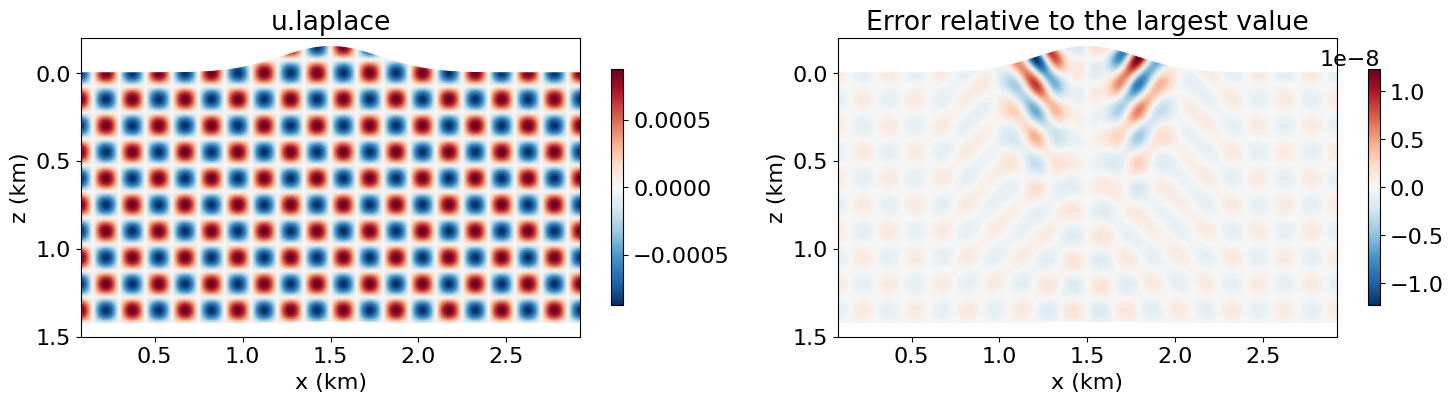

largest error 1.2e-08


In [13]:
# NBVAL_IGNORE_OUTPUT
error = (laplacian_field.data - exact)/np.abs(exact).max()
inner = (slice(8, -8), slice(above, -8))
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
panels = [(laplacian_field.data[inner], 'u.laplace', 'RdBu_r'),
          (error[inner], 'Error relative to the largest value', 'RdBu_r')]
for ax, (values, title, cmap) in zip(axes, panels, strict=True):
    clip = np.abs(values).max()
    image = ax.pcolormesh(x_check[inner]/1000, z_check[inner]/1000, values, cmap=cmap,
                          vmin=-clip, vmax=clip, shading='gouraud')
    ax.set_ylim(1.5, -.2)
    ax.set_aspect('equal')
    ax.set_xlabel('x (km)')
    ax.set_ylabel('z (km)')
    ax.set_title(title)
    fig.colorbar(image, ax=ax, shrink=.6)
plt.tight_layout()
plt.show()
print(f'largest error {np.abs(error[inner]).max():.1e}')

In [14]:
assert np.abs(error[inner]).max() < 1e-6

### Nested derivatives and transposes

Nested derivatives are written as on a `Grid`. `(b*u.dx).dx`, `div(b*grad(u))` or `u.dx.dy` apply the chain rule to each derivative where it is evaluated, with the metric terms there.

Every derivative is the chain rule of what is written: on a flat map it is exactly the derivative of a `Grid`, staggered and shifted ones included.

The transpose `.T` of a physical derivative is its transpose in the inner product weighted by the Jacobian, $\sum J\,u\,v$, the discrete integral over the physical domain: $D^\top_J v = J^{-1} D^\top (J v)$. An operator written with `.T` is therefore exactly the transpose of the one it transposes. An operator written without it, such as `u.laplace` or a pair of staggered derivatives, is symmetric as the continuous operator is, up to its truncation error, which shows where the metric terms vary most (sections 6 and 7).

## 3. The velocity model

Velocity models are usually given on a Cartesian grid. Here the model goes from 1500 m/s above a dipping interface, at a depth of 500 m under the hill, to 2500 m/s below it. It is defined on a `Grid` that extends from 300 m above the datum to the bottom, so that it covers the hill. The interface is smoothed over a few tens of metres: a sharp step in velocity would scatter grid-scale artefacts into the wavefield, on any grid.

In [15]:
model_grid = Grid(shape=(301, 181), extent=(3000., 1800.), origin=(0., -300.))
x_model = np.linspace(0., 3000., 301)[:, None]
z_model = np.linspace(-300., 1500., 181)[None, :]
cartesian_velocity = Function(name='cartesian_velocity', grid=model_grid)
interface_depth = 500. + .1*(x_model - 1500.)
cartesian_velocity.data[:] = 2000. + 500.*np.tanh((z_model - interface_depth)/30.)

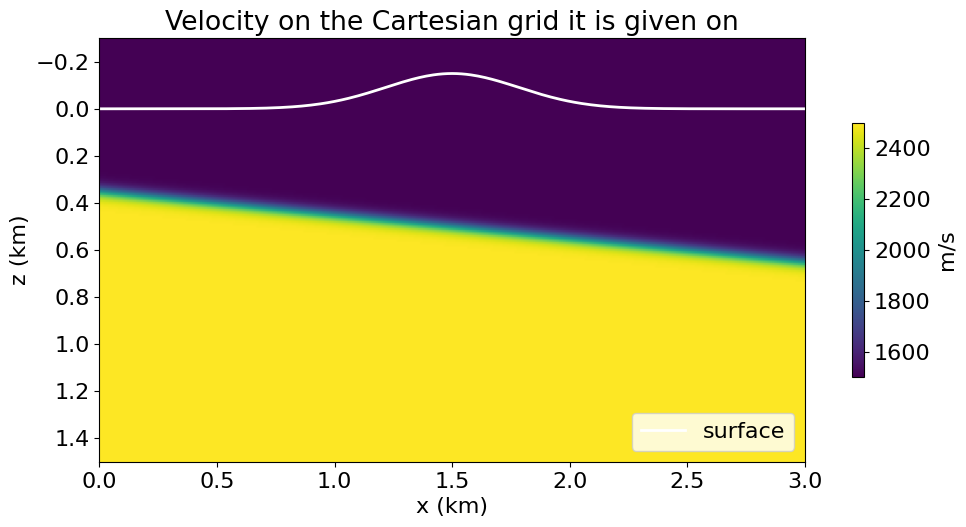

In [16]:
# NBVAL_IGNORE_OUTPUT
fig, ax = plt.subplots(figsize=(12, 5.5))
image = ax.imshow(cartesian_velocity.data.T, cmap='viridis', aspect='equal',
                  extent=[0., 3., 1.5, -.3])
ax.plot(x_line/1000, -elevation(x_line)/1000, 'w', lw=2, label='surface')
ax.set_xlabel('x (km)')
ax.set_ylabel('z (km)')
ax.legend(loc='lower right')
ax.set_title('Velocity on the Cartesian grid it is given on')
fig.colorbar(image, ax=ax, shrink=.6, label='m/s')
plt.show()

The Cartesian model extends above the surface, where the grid does not go. `resample` only reads it at the nodes of the curvilinear grid, from the surface down, so what it holds above the surface does not matter.

`resample(f, cartesian)` sets a `Function` on the curvilinear grid to the Cartesian `Function` interpolated at the physical position of each node, which for this map is an interpolation along each column. The interpolation is multilinear, so the velocity stays within the bounds of the model at its interfaces.

In [17]:
velocity = Function(name='velocity', grid=grid, space_order=8)
resample(velocity, cartesian_velocity)
print(f'velocity between {velocity.data.min():.0f} and {velocity.data.max():.0f} m/s')

velocity between 1500 and 2500 m/s


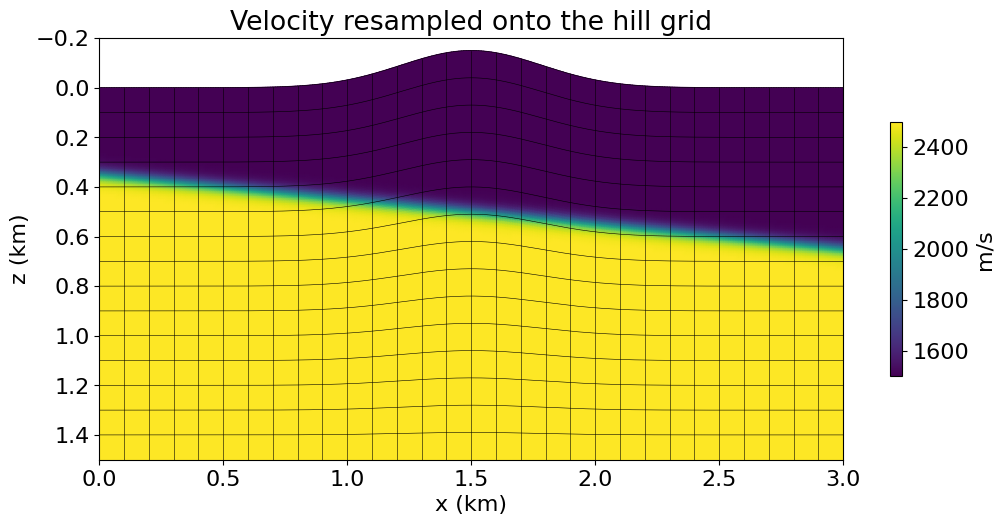

In [18]:
# NBVAL_IGNORE_OUTPUT
fig, ax = plt.subplots(figsize=(12, 5.5))
image = ax.pcolormesh(x_coord, z_coord, velocity.data[below], cmap='viridis',
                      shading='gouraud')
plot_grid_lines(ax, step=10)
ax.set_ylim(1.5, -.2)
ax.set_aspect('equal')
ax.set_xlabel('x (km)')
ax.set_ylabel('z (km)')
ax.set_title('Velocity resampled onto the hill grid')
fig.colorbar(image, ax=ax, shrink=.6, label='m/s')
plt.show()

## 4. Sources, receivers and the free surface

### Sparse functions

The coordinates of sparse functions on a `CurvilinearGrid` are physical, so the source and the receivers are placed exactly as on a `Grid`: the source 20 m below the top of the hill, and a line of 201 receivers 10 m below the surface from $x = 0.5$ km to 2.5 km. Devito maps them onto the grid with the inverse of the map every time an `Operator` runs, so they can be moved between runs.

Interpolation at the receivers works as on a `Grid`. Injection is the transpose of the interpolation in the inner product weighted by the Jacobian: with $P$ the interpolation, it is $J^{-1}P^\top$, which divides what it injects by $J$ at each node it is spread over, so that a point source has the same strength whatever the stretching of the cells around it,

$$
\langle P u, d\rangle = \sum_{\mathrm{nodes}} J\, u\, \left(J^{-1}P^\top d\right).
$$

The time step uses `grid.min_spacing`, the smallest physical distance between neighboring nodes, in place of the grid spacing: $\Delta t = 0.1\,h_{\min}/v_{\max}$, small compared with the stability limit, for the accuracy discussed in section 9.

In [19]:
f0, t0, tn = 10., .12, 1.2  # peak frequency (Hz), wavelet delay and duration (s)
dt = float(.1*grid.min_spacing/velocity.data.max())
nt = int(np.ceil(tn/dt)) + 1
time_values = np.arange(nt)*dt


def ricker(t):
    a = (np.pi*f0*(t - t0))**2
    return (1 - 2*a)*np.exp(-a)


source_position = np.array([[1500., -elevation(1500.) + 20.]])
receiver_x = np.linspace(500., 2500., 201)
receiver_positions = np.stack([receiver_x, -elevation(receiver_x) + 10.], axis=1)

src = SparseTimeFunction(name='src', grid=grid, npoint=1, nt=nt,
                         coordinates=source_position)
src.data[:, 0] = ricker(time_values)
rec = SparseTimeFunction(name='rec', grid=grid, npoint=201, nt=nt,
                         coordinates=receiver_positions)
print(f'{nt} time steps of {1000*dt:.3f} ms')

3446 time steps of 0.348 ms


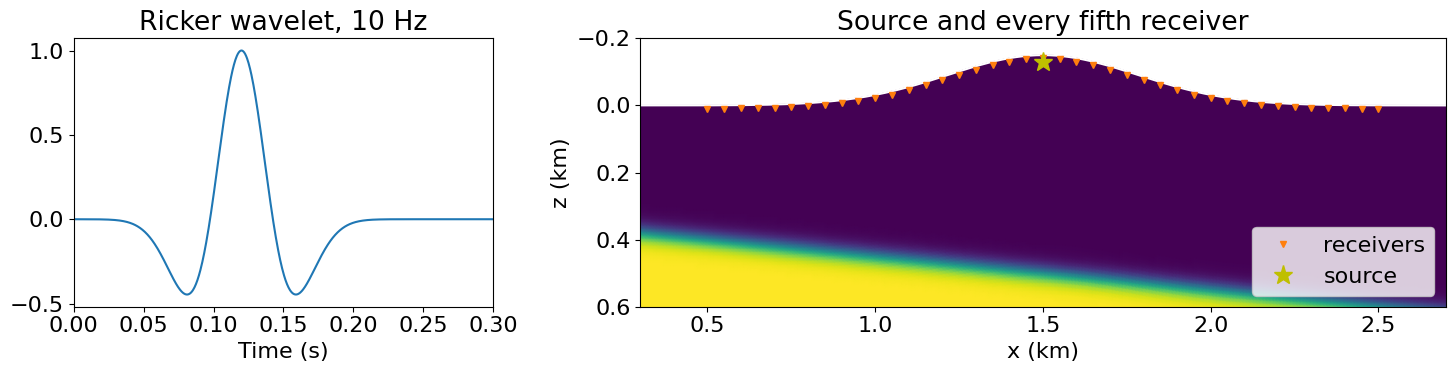

In [20]:
# NBVAL_IGNORE_OUTPUT
fig, axes = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={'width_ratios': [1, 2]})
axes[0].plot(time_values, src.data[:, 0])
axes[0].set_xlim(0., .3)
axes[0].set_xlabel('Time (s)')
axes[0].set_title(f'Ricker wavelet, {f0:.0f} Hz')
image = axes[1].pcolormesh(x_coord, z_coord, velocity.data[below], cmap='viridis',
                           shading='gouraud')
axes[1].plot(x_coord[:, 0], z_coord[:, 0], 'w', lw=1.5)
axes[1].plot(*(receiver_positions[::5]/1000).T, 'v', color='C1', ms=4, label='receivers')
axes[1].plot(*(source_position/1000).T, 'y*', ms=14, label='source')
axes[1].set_xlim(.3, 2.7)
axes[1].set_ylim(.6, -.2)
axes[1].set_aspect('equal')
axes[1].set_xlabel('x (km)')
axes[1].set_ylabel('z (km)')
axes[1].legend(loc='lower right')
axes[1].set_title('Source and every fifth receiver')
plt.tight_layout()
plt.show()

### The free surface

The pressure vanishes on the surface. On a `Grid` this is imposed with an odd mirror: the surface row $s$ is set to zero, and each row $z$ above it to minus the row as far below it, $u(z) = -u(2s - z)$. The free surface is written the same way on a `CurvilinearGrid`, as equations after each update of `u`, over `SubDomain`s of the surface row and of the `above` rows above it.

The surface is the row $\eta = 0$ of the grid, flat in computational space, and indices are computational, as on a `Grid`: in computational space the mirror is the reflection normal to the surface, $u(\xi, -\eta) = -u(\xi, \eta)$, which sets $u = 0$ on the surface whatever the direction of the grid lines. The geometry of the surface enters the propagation through the metric terms of the derivatives; section 9 measures the result against an analytic solution under a slope.

The equations only write the surface row and the rows above it, which are part of the grid: the halo is never touched. Their `SubDomain`s are the rows of the seismic examples, `RowsDomain`, built once per grid.

In [21]:
u = TimeFunction(name='u', grid=grid, space_order=8, time_order=2)
m = Function(name='m', grid=grid, space_order=8)
m.data[:] = 1/velocity.data**2


def surface_rows(grid, above):
    """The rows above the surface, the surface row, and the rows they mirror."""
    return FreeSurfaceRows(above=RowsDomain('above', 0, above, grid),
                           surface=RowsDomain('surface', above, 1, grid),
                           mirrored=RowsDomain('mirrored', above + 1, above, grid))


def free_surface(field, rows):
    """Zero `field` on the surface row and mirror it, odd, into the rows above."""
    vertical = field.function.grid.dimensions[-1]
    s = rows.surface.start
    return [Eq(field, 0, subdomain=rows.surface),
            Eq(field, -field.subs(vertical, 2*s - vertical), subdomain=rows.above)]


rows = surface_rows(grid, above)
surface = free_surface(u.forward, rows)
surface

[Eq(u(t + dt, x, y), 0), Eq(u(t + dt, x, y), -u(t + dt, x, 16 - y))]

## 5. The simulation

The acoustic wave equation

$$
m\,\frac{\partial^2 u}{\partial t^2} - \nabla\cdot\nabla u = s, \qquad m = \frac{1}{v^2},
$$

is written as on a `Grid`, and `solve` gives the leapfrog update. The update runs over the whole grid; the source is injected, then the free surface overwrites the surface row and the rows above it, so that the mirror includes the source wherever it is spread close to the surface.

In [22]:
pde = m*u.dt2 - u.laplace
update = Eq(u.forward, solve(pde, u.forward))
op = Operator([update] +
              src.inject(field=u.forward, expr=src*dt**2/m) +
              surface +
              rec.interpolate(expr=u))

We run the operator in segments, to keep snapshots of the wavefield at 0.3 s, 0.55 s and 0.8 s. The first segment starts at the time step 1, where `op.apply` starts by default: the update reads `u` one step back.

In [23]:
# NBVAL_IGNORE_OUTPUT
snapshots = []
start = 1
for snapshot_time in [.3, .55, .8]:
    step = int(snapshot_time/dt)
    summary = op.apply(dt=dt, time_m=start, time_M=step)
    snapshots.append((snapshot_time, u.data[(step + 1) % 3].copy()))
    start = step + 1
summary = op.apply(dt=dt, time_m=start, time_M=nt - 2)

Operator `Kernel` ran in 0.14 s


Operator `Kernel` ran in 0.12 s


Operator `Kernel` ran in 0.11 s


Operator `Kernel` ran in 0.18 s


Drawn at the physical position of the nodes, the snapshots show the direct wave, its reflection off the hill with the polarity flip of a free surface, and the reflection off the dipping interface (dashed).

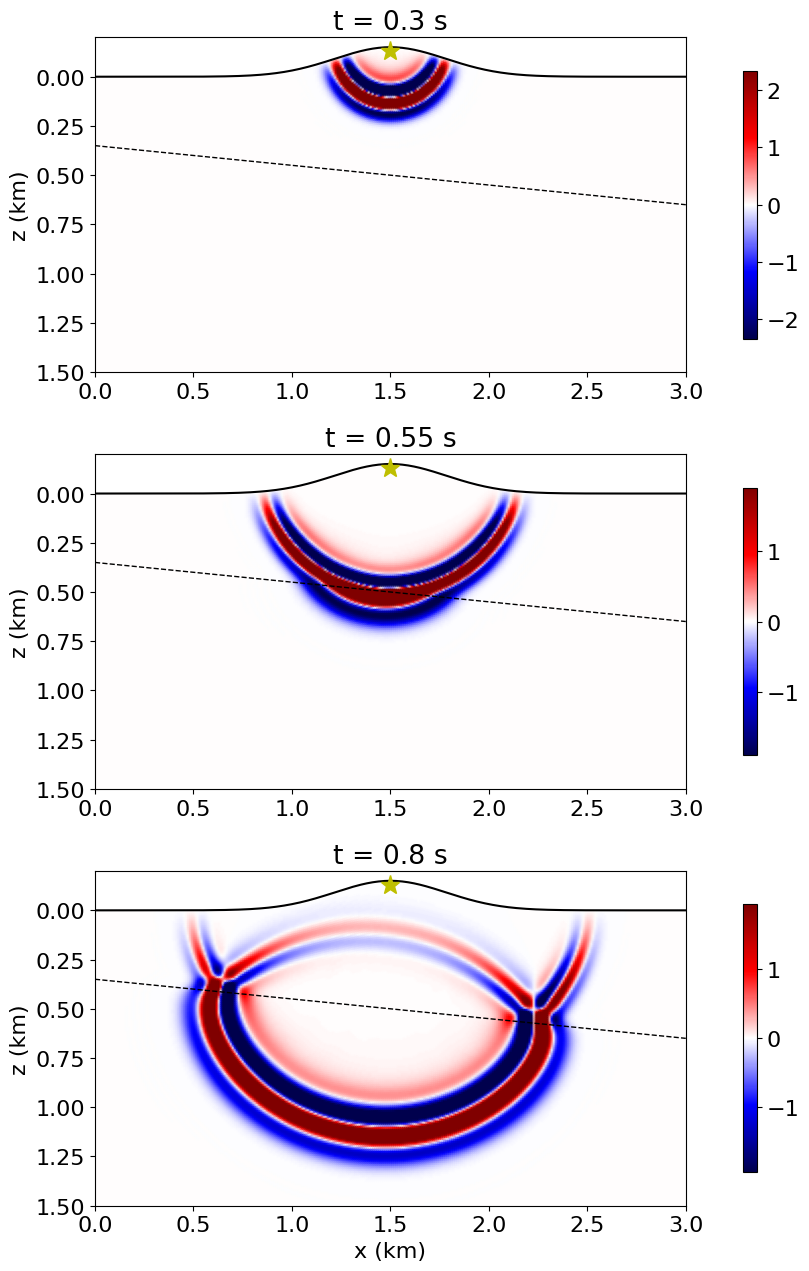

In [24]:
# NBVAL_IGNORE_OUTPUT
fig, axes = plt.subplots(3, 1, figsize=(12, 13))
interface = 500. + .1*(np.linspace(0., 3000., 301) - 1500.)
for ax, (snapshot_time, snapshot) in zip(axes, snapshots, strict=True):
    clip = .3*np.abs(snapshot[below]).max()
    image = ax.pcolormesh(x_coord, z_coord, snapshot[below], cmap='seismic',
                          vmin=-clip, vmax=clip, shading='gouraud')
    ax.plot(x_coord[:, 0], z_coord[:, 0], 'k', lw=1.5)
    ax.plot(np.linspace(0., 3., 301), interface/1000, 'k--', lw=1)
    ax.plot(*(source_position/1000).T, 'y*', ms=14)
    ax.set_ylim(1.5, -.2)
    ax.set_aspect('equal')
    ax.set_ylabel('z (km)')
    ax.set_title(f't = {snapshot_time} s')
    fig.colorbar(image, ax=ax, shrink=.8)
axes[-1].set_xlabel('x (km)')
plt.tight_layout()
plt.show()

The shot record shows the same events at the receivers. The receivers are only 10 m below the free surface, where the pressure is close to zero, so the direct wave is strong only next to the source, and the reflection off the interface arrives between 0.9 s and 1.2 s, its shape bent by the hill. The grid has no absorbing boundary, so the record stops at 1.2 s, before the reflections off the sides and the bottom of the grid arrive.

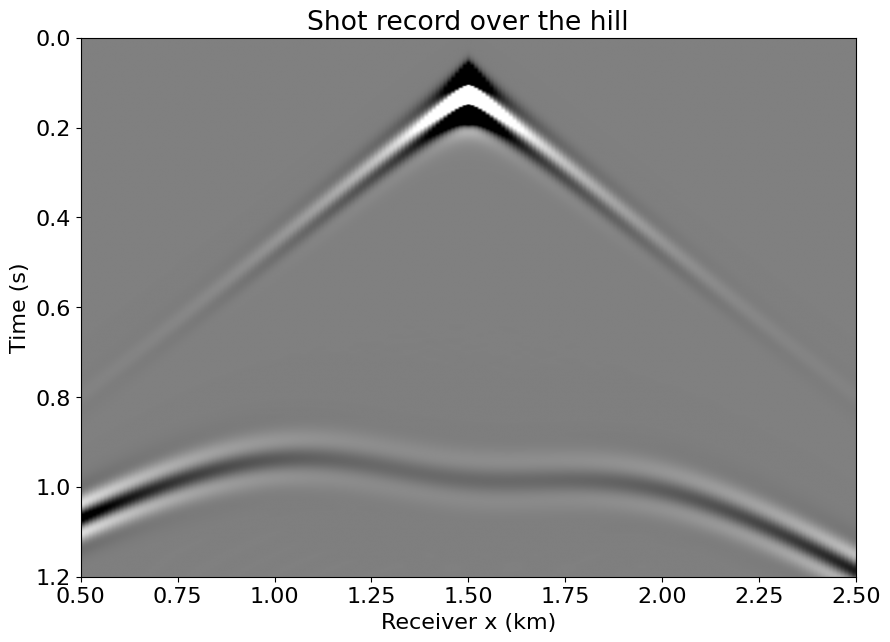

In [25]:
# NBVAL_IGNORE_OUTPUT
fig, ax = plt.subplots(figsize=(10, 7))
clip = .05*np.abs(rec.data).max()
ax.imshow(rec.data, aspect='auto', cmap='gray', vmin=-clip, vmax=clip,
          extent=[receiver_x[0]/1000, receiver_x[-1]/1000, tn, 0])
ax.set_xlabel('Receiver x (km)')
ax.set_ylabel('Time (s)')
ax.set_title('Shot record over the hill')
plt.show()

Three traces of the record, each scaled to its largest value. Above the source the direct wave dominates. At 0.5 km from it, the direct wave arrives at 0.45 s and the reflection off the interface at 1 s, with a similar amplitude. At 1 km, the direct wave, which travels just under the free surface, almost vanishes, and the reflection, at 1.15 s, dominates.

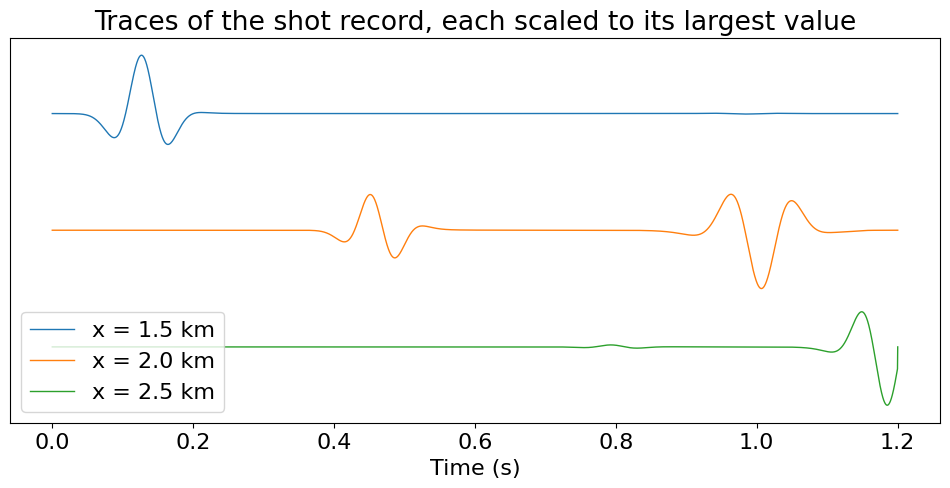

In [26]:
# NBVAL_IGNORE_OUTPUT
fig, ax = plt.subplots(figsize=(12, 5))
for shift, offset in enumerate((0., 500., 1000.)):
    index = np.argmin(np.abs(receiver_x - 1500. - offset))
    trace = rec.data[:, index]
    ax.plot(time_values, trace/np.abs(trace).max() - 2*shift, lw=1,
            label=f'x = {receiver_x[index]/1000:.1f} km')
ax.set_yticks([])
ax.set_xlabel('Time (s)')
ax.set_title('Traces of the shot record, each scaled to its largest value')
ax.legend(loc='lower left')
plt.show()

## 6. The adjoint

Inversion and imaging need the adjoint of the modelling, which back-propagates data from the receivers. Injection is the transpose of the interpolation in the inner product weighted by the Jacobian, and the adjoint wave equation is written as on a `Grid`, the same equation run backward in time:

$$
m\,\frac{\partial^2 q}{\partial t^2} - \Delta q = P^\top d.
$$

The free surface mirrors the field into the rows above the surface, $u(z) = -u(2s - z)$. Its transpose, in the same inner product, folds what the adjoint update leaves in these rows back onto the rows they mirror, then sets them to zero,

$$
q(2s - z) \leftarrow q(2s - z) - \frac{c(2s - z)}{J(2s - z)}\, J(z)\, \frac{q(z)}{c(z)},
$$

with $c = \Delta t^2/m$ the factor of the Laplacian in the update, the grid having no absorbing layer here. The adjoint update is computed in the rows above the surface too, and the fold is applied after the data are injected, as the mirror is after the source.

In [27]:
q = TimeFunction(name='q', grid=grid, space_order=8, time_order=2)
src_adjoint = SparseTimeFunction(name='src_adjoint', grid=grid, npoint=1, nt=nt,
                                 coordinates=source_position)
residual = SparseTimeFunction(name='residual', grid=grid, npoint=201, nt=nt,
                              coordinates=receiver_positions)


def free_surface_adjoint(field, coefficient, rows):
    """
    The transpose of `free_surface` after an update of `field` that leaves
    `coefficient` times the Laplacian in the rows above the surface: these rows
    folded onto the rows below them, then zero, with the surface row.
    """
    grid = field.function.grid
    vertical = grid.dimensions[-1]
    s = rows.surface.start
    folded = (grid.jacobian*field/coefficient).subs(vertical, 2*s - vertical)
    return [Inc(field, -coefficient*grid.inverse_jacobian*folded,
                subdomain=rows.mirrored),
            Eq(field, 0, subdomain=rows.above),
            Eq(field, 0, subdomain=rows.surface)]


pde_adjoint = m*q.dt2 - q.laplace
update_adjoint = Eq(q.backward, solve(pde_adjoint, q.backward))
op_adjoint = Operator([update_adjoint] +
                      residual.inject(field=q.backward, expr=residual*dt**2/m) +
                      free_surface_adjoint(q.backward, dt**2/m, rows) +
                      src_adjoint.interpolate(expr=q))

The adjoint is checked with the dot test: for the modelling $F$ from the source wavelet $s$ to the data, and any data $d$,

$$
\langle F s, d\rangle = \langle s, F^\top d\rangle.
$$

We take the shot record above as $F s$, and random data for $d$.

In [28]:
# NBVAL_IGNORE_OUTPUT
residual.data[:] = np.random.default_rng(0).standard_normal(residual.data.shape)
summary = op_adjoint.apply(dt=dt, time_M=nt - 2)

Operator `Kernel` ran in 0.54 s


In [29]:
# NBVAL_IGNORE_OUTPUT
forward = np.dot(rec.data.ravel(), residual.data.ravel())
adjoint = np.dot(src.data.ravel(), src_adjoint.data.ravel())
print(f'<Fs, d> = {forward:.6e}, <s, F^T d> = {adjoint:.6e}, '
      f'relative difference {abs(forward - adjoint)/abs(forward):.1e}')

<Fs, d> = -1.673875e+02, <s, F^T d> = -1.672198e+02, relative difference 1.0e-03


In [30]:
assert np.isclose(forward, adjoint, rtol=2e-3)

The two agree to about 1e-3 over the 3400 time steps. `q.laplace` is the Laplacian by the chain rule, whose discretization is symmetric in the inner product weighted by the Jacobian up to its truncation error: the adjoint written as on a `Grid` is the transpose of the modelling to that level. Written with the transposes of its second derivatives, `q.dx2.T + q.dy2.T`, which are exact transposes, the adjoint would be exact. With the shot record itself as the data, the adjoint propagates it back into the model: the wavefield converges back toward the source as time decreases, while the reflections off the hill and the interface retrace their paths.

In [31]:
# NBVAL_IGNORE_OUTPUT
residual.data[:] = rec.data
q.data[:] = 0
backward_snapshots = []
stop = nt - 2
for snapshot_time in [.8, .5, .2]:
    step = int(snapshot_time/dt)
    summary = op_adjoint.apply(dt=dt, time_m=step, time_M=stop)
    backward_snapshots.append((snapshot_time, q.data[(step - 1) % 3].copy()))
    stop = step - 1

Operator `Kernel` ran in 0.18 s


Operator `Kernel` ran in 0.13 s


Operator `Kernel` ran in 0.13 s


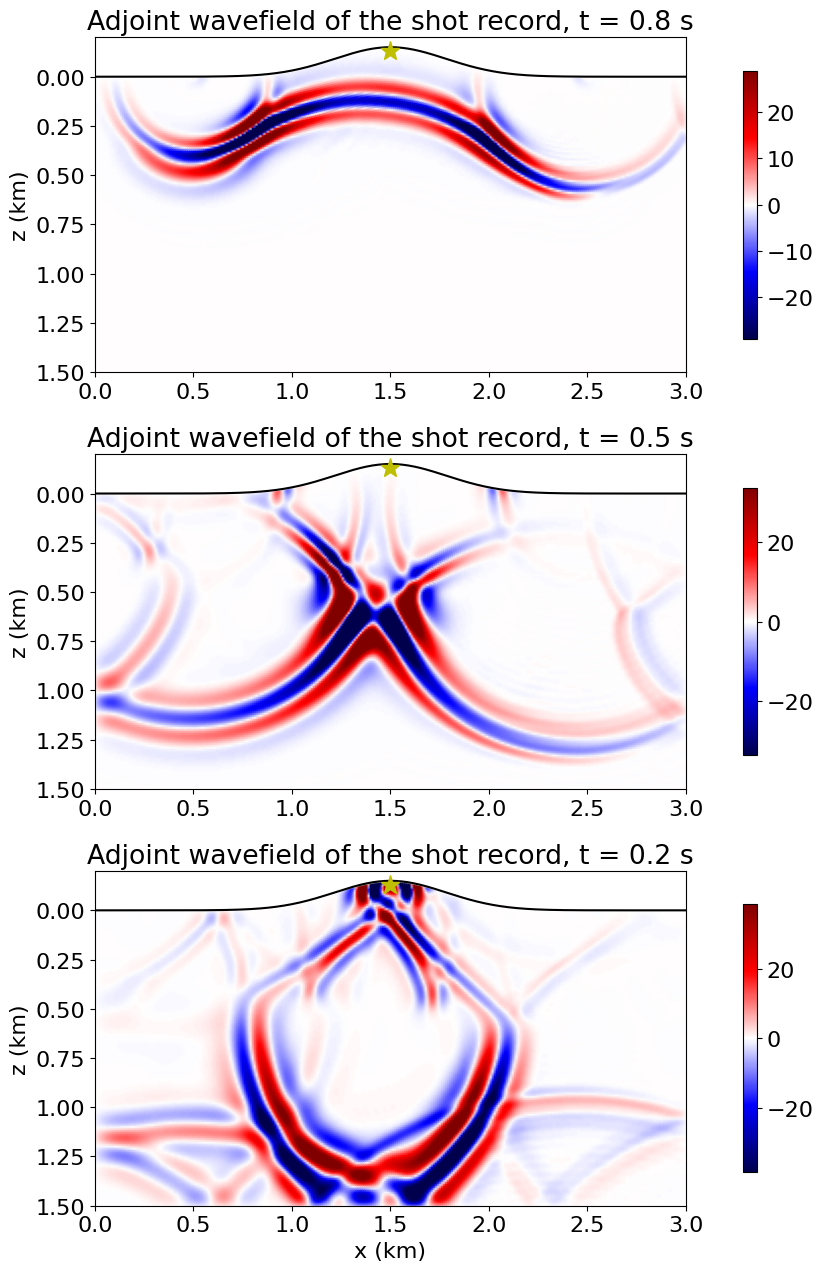

In [32]:
# NBVAL_IGNORE_OUTPUT
fig, axes = plt.subplots(3, 1, figsize=(12, 13))
for ax, (snapshot_time, snapshot) in zip(axes, backward_snapshots, strict=True):
    clip = .3*np.abs(snapshot[below]).max()
    image = ax.pcolormesh(x_coord, z_coord, snapshot[below], cmap='seismic',
                          vmin=-clip, vmax=clip, shading='gouraud')
    ax.plot(x_coord[:, 0], z_coord[:, 0], 'k', lw=1.5)
    ax.plot(*(source_position/1000).T, 'y*', ms=14)
    ax.set_ylim(1.5, -.2)
    ax.set_aspect('equal')
    ax.set_ylabel('z (km)')
    ax.set_title(f'Adjoint wavefield of the shot record, t = {snapshot_time} s')
    fig.colorbar(image, ax=ax, shrink=.8)
axes[-1].set_xlabel('x (km)')
plt.tight_layout()
plt.show()

## 7. Variable density

With a variable density $\rho$, the acoustic wave equation for the pressure $p$ is

$$
\frac{1}{\kappa}\,\frac{\partial^2 p}{\partial t^2} - \nabla\cdot\left(b\,\nabla p\right) = s,
\qquad \kappa = \rho v^2, \qquad b = \frac{1}{\rho},
$$

with $\kappa$ the bulk modulus and $b$ the buoyancy. It is written exactly as on a `Grid`, e.g. as in the variable-density recipes, with pairs of staggered derivatives: the derivative along each axis to the half points after the nodes, times the buoyancy there, then the derivative back to the nodes,

$$
\nabla\cdot\left(b\,\nabla p\right) \approx \sum_{d} D^-_{d}\left(b_{d+1/2}\, D^+_{d}\, p\right),
$$

`(b.subs(x, x + h_x/2)*p.dx(x0=x + h_x/2)).dx(x0=x - h_x/2)` along $x$, and the same along $z$. The density follows the velocity by Gardner's relation, $\rho = 0.31\,v^{1/4}$, in g/cm$^3$ with $v$ in m/s, which gives the interface a density contrast of 14 percent on top of its velocity contrast.

In [33]:
rho = .31*velocity.data**.25
kappa = Function(name='kappa', grid=grid, space_order=8)
b = Function(name='b', grid=grid, space_order=8)
initialize_function(kappa, rho*velocity.data**2, 0)
initialize_function(b, 1/rho, 0)
print(f'density between {rho.min():.2f} and {rho.max():.2f} g/cm^3')

density between 1.93 and 2.19 g/cm^3


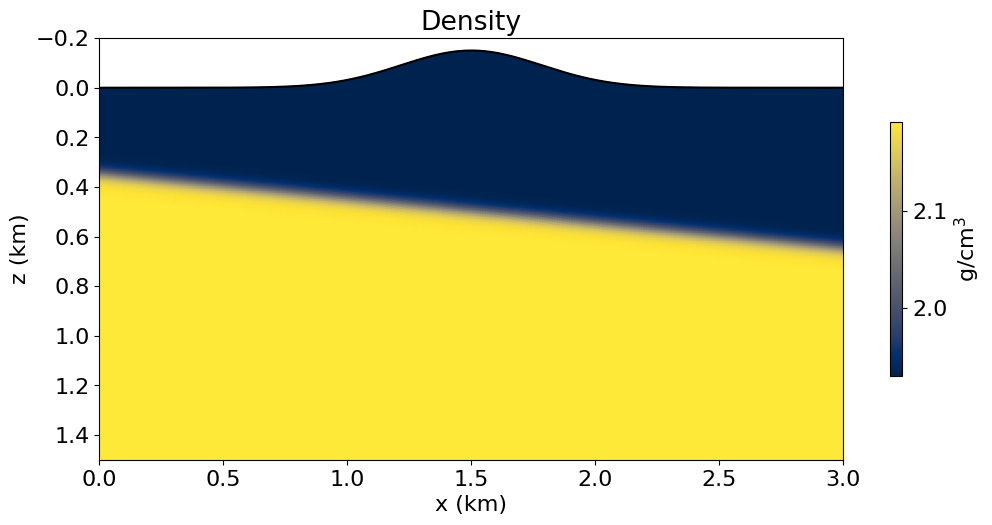

In [34]:
# NBVAL_IGNORE_OUTPUT
fig, ax = plt.subplots(figsize=(12, 5.5))
image = ax.pcolormesh(x_coord, z_coord, rho[below], cmap='cividis', shading='gouraud')
ax.plot(x_coord[:, 0], z_coord[:, 0], 'k', lw=1.5)
ax.set_ylim(1.5, -.2)
ax.set_aspect('equal')
ax.set_xlabel('x (km)')
ax.set_ylabel('z (km)')
ax.set_title('Density')
fig.colorbar(image, ax=ax, shrink=.6, label='g/cm$^3$')
plt.show()

The accuracy of the operator on a curved grid can be checked against its analytic value for smooth fields, $p = \sin(kx)\cos(kz)$ and $b = 1 + \frac{1}{2}\sin(kx + 1)\sin(0.7kz)$ with a wavelength of 400 m, for which $\nabla\cdot(b\nabla p) = b\,\Delta p + \nabla b\cdot\nabla p$, on a hill grid at two spacings. It is compared with two other ways of writing it, which behave the same way on a `Grid`:

* `div(b*grad(p, shift=.5), shift=-.5)` takes the same staggered derivatives but reads $b$ at the nodes, half a cell away from the gradient it multiplies, which makes it first order. The staggered form reads $b$ at the half points, averaged there from its two neighboring nodes, which makes it second order;
* `div(b*grad(p))` takes centered derivatives at the nodes. It is accurate for smooth fields, but the product of two centered first derivatives does not see the shortest wavelength of the grid, which a point source excites and which then stays around the source.

In [35]:
def div_b_grad(b, p):
    """div(b grad p) as staggered pairs, b at the half points, as on a Grid."""
    return sum((b.subs(d, d + d.spacing/2)*p.diff(d, x0={d: d + d.spacing/2}))
               .diff(d, x0={d: d - d.spacing/2}) for d in p.grid.dimensions)


def div_b_grad_shift(b, p):
    return div(b*grad(p, shift=.5), shift=-.5)


def div_b_grad_centered(b, p):
    return div(b*grad(p))


forms = {'staggered, b at the half points': div_b_grad,
         'shift, b at the nodes': div_b_grad_shift,
         'centered': div_b_grad_centered}


def operator_error(spacing, form):
    n = int(1000/spacing) + 1
    hill = CurvilinearGrid(shape=(n, n), extent=(1000., 1000.), dtype=np.float64,
                           mapping=TerrainFollowing(
                               lambda x: -100.*np.exp(-((x - 500.)/200.)**2)))
    k = 2*np.pi/400.
    xc, zc = (c.data for c in hill.coordinates)
    pc = Function(name='pc', grid=hill, space_order=8)
    bc = Function(name='bc', grid=hill, space_order=8)
    pc.data[:] = np.sin(k*xc)*np.cos(k*zc)
    bc.data[:] = 1 + .5*np.sin(k*xc + 1.)*np.sin(.7*k*zc)
    gradient = (k*np.cos(k*xc)*np.cos(k*zc), -k*np.sin(k*xc)*np.sin(k*zc))
    gradient_b = (.5*k*np.cos(k*xc + 1.)*np.sin(.7*k*zc),
                  .35*k*np.sin(k*xc + 1.)*np.cos(.7*k*zc))
    exact = (bc.data*(-2*k**2)*pc.data +
             sum(a*b for a, b in zip(gradient, gradient_b, strict=True)))
    result = Function(name='result', grid=hill, space_order=8)
    Operator(Eq(result, forms[form](bc, pc))).apply()
    inner = (slice(10, -10), slice(10, -10))
    return np.abs(result.data[inner] - exact[inner]).max()/np.abs(exact[inner]).max()

In [36]:
# NBVAL_IGNORE_OUTPUT
errors = {form: [operator_error(h, form) for h in (20., 10.)] for form in forms}
for form, (coarse, fine) in errors.items():
    print(f'{form:32s}: error {coarse:.1e} at 20 m, {fine:.1e} at 10 m, '
          f'order {np.log2(coarse/fine):.1f}')

Operator `Kernel` ran in 0.01 s


Operator `Kernel` ran in 0.01 s


Operator `Kernel` ran in 0.01 s


Operator `Kernel` ran in 0.01 s


Operator `Kernel` ran in 0.01 s


Operator `Kernel` ran in 0.01 s


staggered, b at the half points : error 3.1e-03 at 20 m, 8.0e-04 at 10 m, order 2.0
shift, b at the nodes           : error 3.0e-02 at 20 m, 1.5e-02 at 10 m, order 1.0
centered                        : error 4.8e-05 at 20 m, 3.0e-07 at 10 m, order 7.3


In [37]:
assert np.log2(errors['staggered, b at the half points'][0] /
               errors['staggered, b at the half points'][1]) > 1.8

The update and the source carry $\Delta t^2\kappa$ where the constant-density case had $\Delta t^2/m$; with a constant density both are the same equation.

In [38]:
# NBVAL_IGNORE_OUTPUT
p = TimeFunction(name='p', grid=grid, space_order=8, time_order=2)
rec_density = SparseTimeFunction(name='rec_density', grid=grid, npoint=201, nt=nt,
                                 coordinates=receiver_positions)

coefficient = dt**2*kappa
pde_density = p.dt2/kappa - div_b_grad(b, p)
update_density = Eq(p.forward, solve(pde_density, p.forward))
op_density = Operator([update_density] +
                      src.inject(field=p.forward, expr=src*coefficient) +
                      free_surface(p.forward, rows) +
                      rec_density.interpolate(expr=p))
summary = op_density.apply(dt=dt, time_M=nt - 2)

Operator `Kernel` ran in 1.38 s


Divided by the density above the interface, the direct wave and the free-surface reflections of the variable-density record are those of the constant-density one: in the pressure formulation, a constant density only scales the field. The reflection off the interface is stronger, as its reflection coefficient depends on the contrast of impedance $\rho v$ rather than of velocity alone: at normal incidence

$$
R = \frac{\rho_2 v_2 - \rho_1 v_1}{\rho_2 v_2 + \rho_1 v_1},
$$

which is 0.25 with a constant density and 0.31 with this one, a ratio of 1.23. The reflection recorded above the source, off an interface that dips by 6 degrees, gives a ratio close to it.

In [39]:
# NBVAL_IGNORE_OUTPUT
early = time_values < .5
rho_above = .31*1500**.25
ratio = np.abs(rec_density.data[early]).max()/np.abs(rec.data[early]).max()
print(f'direct wave amplitude ratio {ratio:.3f}, density above the interface '
      f'{rho_above:.3f}')

late = time_values > .85
centre = np.argmin(np.abs(receiver_x - 1500.))
reflection = (np.abs(rec_density.data[late, centre]).max()/rho_above /
              np.abs(rec.data[late, centre]).max())
impedance = [(.31*v**.25*v) for v in (1500., 2500.)]
predicted = ((impedance[1] - impedance[0])/(impedance[1] + impedance[0]))/.25
print(f'interface reflection ratio {reflection:.3f}, normal incidence {predicted:.3f}')

direct wave amplitude ratio 1.930, density above the interface 1.929
interface reflection ratio 1.245, normal incidence 1.235


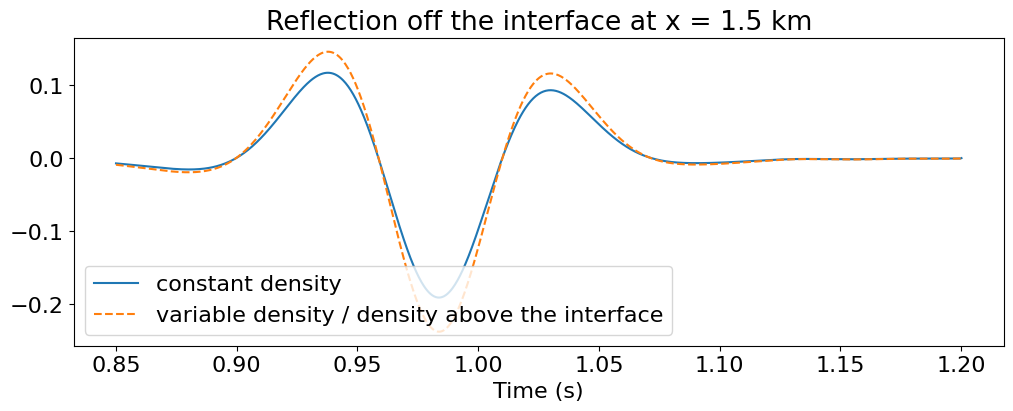

In [40]:
# NBVAL_IGNORE_OUTPUT
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(time_values[late], rec.data[late, centre], label='constant density')
ax.plot(time_values[late], rec_density.data[late, centre]/rho_above, '--',
        label='variable density / density above the interface')
ax.set_xlabel('Time (s)')
ax.set_title('Reflection off the interface at x = 1.5 km')
ax.legend()
plt.show()

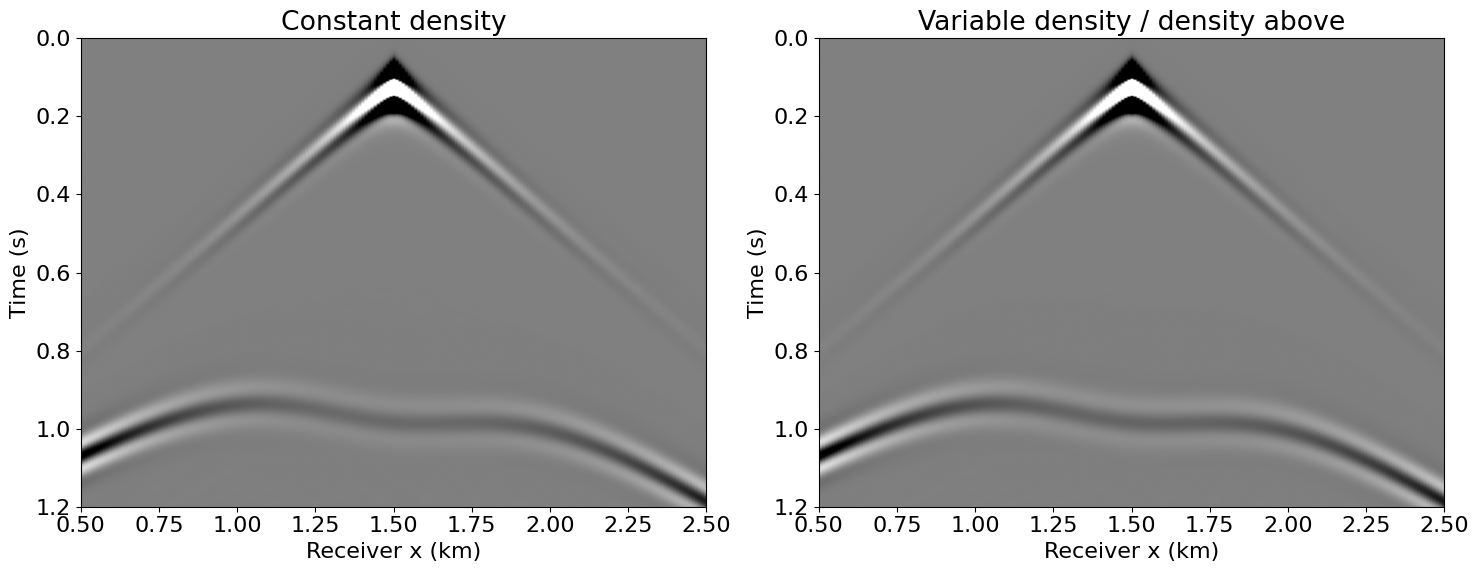

In [41]:
# NBVAL_IGNORE_OUTPUT
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, data, title in zip(axes, [rec.data, rec_density.data/rho_above],
                           ['Constant density', 'Variable density / density above'],
                           strict=True):
    clip = .05*np.abs(rec.data).max()
    ax.imshow(data, aspect='auto', cmap='gray', vmin=-clip, vmax=clip,
              extent=[receiver_x[0]/1000, receiver_x[-1]/1000, tn, 0])
    ax.set_xlabel('Receiver x (km)')
    ax.set_ylabel('Time (s)')
    ax.set_title(title)
plt.tight_layout()
plt.show()

$\nabla\cdot(b\nabla p)$ is self-adjoint, so the adjoint is the same equation run backward in time, as on a `Grid`, with the data injected as the source and the free surface transposed by the fold of section 6, with $c = \Delta t^2\kappa$.

In [42]:
# NBVAL_IGNORE_OUTPUT
q.data[:] = 0
residual.data[:] = np.random.default_rng(0).standard_normal(residual.data.shape)
pde_density_adjoint = q.dt2/kappa - div_b_grad(b, q)
update_density_adjoint = Eq(q.backward, solve(pde_density_adjoint, q.backward))
op_density_adjoint = Operator([update_density_adjoint] +
                              residual.inject(field=q.backward,
                                              expr=residual*coefficient) +
                              free_surface_adjoint(q.backward, coefficient, rows) +
                              src_adjoint.interpolate(expr=q))
summary = op_density_adjoint.apply(dt=dt, time_M=nt - 2)

Operator `Kernel` ran in 1.38 s


In [43]:
# NBVAL_IGNORE_OUTPUT
forward = np.dot(rec_density.data.ravel(), residual.data.ravel())
adjoint = np.dot(src.data.ravel(), src_adjoint.data.ravel())
print(f'<Fs, d> = {forward:.6e}, <s, F^T d> = {adjoint:.6e}, '
      f'relative difference {abs(forward - adjoint)/abs(forward):.1e}')

<Fs, d> = -3.413968e+02, <s, F^T d> = -3.410692e+02, relative difference 9.6e-04


In [44]:
assert np.isclose(forward, adjoint, rtol=2e-3)

The two agree to about 1e-3, the truncation error of the staggered pairs under the hill, as the constant-density adjoint of section 6 agrees to that of `u.laplace`.

## 8. Elastic waves

The elastic wave equation, in velocity $\mathbf{v}$ and stress $\boldsymbol{\tau}$,

$$
\frac{\partial \mathbf{v}}{\partial t} = b\,\nabla\cdot\boldsymbol{\tau}, \qquad
\frac{\partial \boldsymbol{\tau}}{\partial t} = \lambda\,(\nabla\cdot\mathbf{v})\,\mathbf{I} + \mu\left(\nabla\mathbf{v} + \nabla\mathbf{v}^\top\right),
$$

is also written exactly as on a `Grid` (see the elastic tutorial of the seismic examples), with a `VectorTimeFunction` and a `TensorTimeFunction`, staggered as on a `Grid`: each component of `div` and `grad` is a physical derivative to the point of the component it updates, with the metric terms there.

A vertical force 700 m below the top of the hill radiates both P and S waves. A traction-free surface, the free surface of an elastic medium, needs boundary rows of its own, beyond this tutorial; here the run stops before any wave reaches the surface.

In [45]:
vp_elastic, vs_elastic, rho_elastic = 2000., 1000., 1.8
v = VectorTimeFunction(name='v', grid=grid, space_order=8, time_order=1)
tau = TensorTimeFunction(name='tau', grid=grid, space_order=8, time_order=1)
mu = rho_elastic*vs_elastic**2
lam = rho_elastic*vp_elastic**2 - 2*mu

dt_elastic = float(.1*grid.min_spacing/vp_elastic)
nt_elastic = int(.3/dt_elastic)
force = SparseTimeFunction(name='force', grid=grid, npoint=1, nt=nt_elastic,
                           coordinates=np.array([[1500., -elevation(1500.) + 700.]]))
force.data[:, 0] = ricker(np.arange(nt_elastic)*dt_elastic)

pde_v = v.dt - div(tau)/rho_elastic
pde_tau = tau.dt - lam*diag(div(v.forward)) - \
    mu*(grad(v.forward) + grad(v.forward).transpose(inner=False))
op_elastic = Operator([Eq(v.forward, solve(pde_v, v.forward)),
                       Eq(tau.forward, solve(pde_tau, tau.forward))] +
                      force.inject(field=v.forward[1], expr=force*dt_elastic/rho_elastic))

In [46]:
# NBVAL_IGNORE_OUTPUT
summary = op_elastic.apply(dt=dt_elastic, time_M=nt_elastic - 2)

Operator `Kernel` ran in 0.19 s


At 0.3 s, the vertical velocity shows the P wave, at 2000 m/s, ahead of the S wave, at 1000 m/s, both with the radiation pattern of a vertical force, the P wave strongest along the force and the S wave across it. The fronts are circles in physical space, drawn here at the physical positions of the nodes, while the grid under them follows the hill.

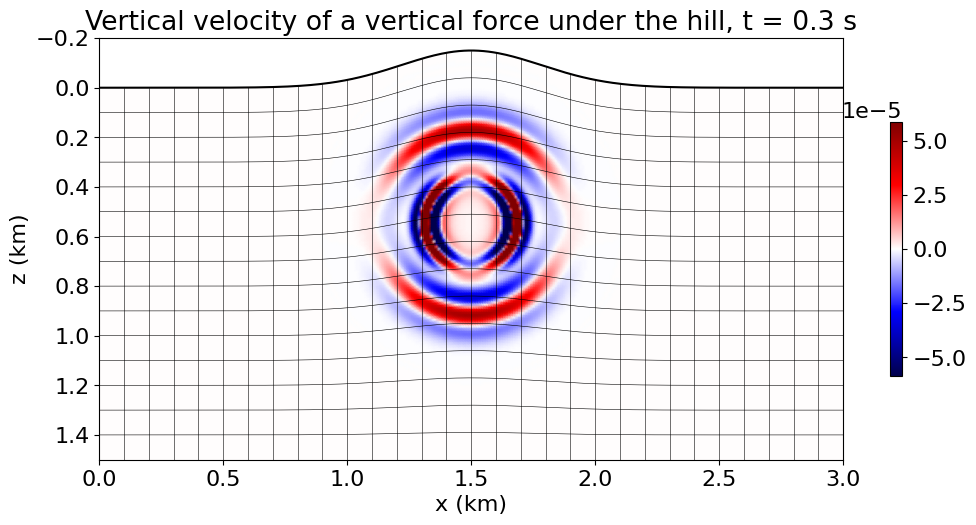

In [47]:
# NBVAL_IGNORE_OUTPUT
vz = v[1].data[(nt_elastic - 1) % 2][below]
fig, ax = plt.subplots(figsize=(12, 5.5))
clip = .3*np.abs(vz).max()
image = ax.pcolormesh(x_coord, z_coord, vz, cmap='seismic', vmin=-clip, vmax=clip,
                      shading='gouraud')
plot_grid_lines(ax, step=10)
ax.plot(x_coord[:, 0], z_coord[:, 0], 'k', lw=1.5)
ax.set_ylim(1.5, -.2)
ax.set_aspect('equal')
ax.set_xlabel('x (km)')
ax.set_ylabel('z (km)')
ax.set_title('Vertical velocity of a vertical force under the hill, t = 0.3 s')
fig.colorbar(image, ax=ax, shrink=.6)
plt.show()

## 9. How accurate is it? A tilted plane

The hill has no analytic solution, so we check the accuracy on the simplest topography that has one, a plane. Over a homogeneous half-space bounded by a planar free surface, the wavefield is the field of the source minus the field of its image across the plane (the image source). We take a plane dipping at 0.1 from $z = 0$ at $x = 0$, over a medium at 1500 m/s, on a grid of the same size, spacing and time-step rule as the hill.

In 2D, the free-space solution of $m\,\partial_t^2 u - \Delta u = A\,s(t)\,\delta(\mathbf{x} - \mathbf{x}_s)$ at a distance $r$ from the source, with $c$ the velocity and $\tau_0 = r/c$, is

$$
u(r, t) = \frac{A}{2\pi}\int_0^{\cosh^{-1}(t/\tau_0)} s(t - \tau_0\cosh\theta)\,d\theta \qquad\text{for } t > \tau_0,
$$

and zero before. The source injected with weight $\Delta t^2/m$ has amplitude $A = h_\xi h_\eta$, the area of a computational cell (10 m by 10 m here).

In [48]:
def free_space(r, t, amplitude, c=1500.):
    # The trapezoidal rule over theta = u*arccosh(t/tau0), u in [0, 1], one node
    # u at a time for all times and distances, zero for t <= tau0 where arccosh
    # vanishes
    tau0 = r[None, :]/c
    end = np.arccosh(np.maximum(t[:, None]/tau0, 1.))
    unit = np.linspace(0, 1, 801)
    weights = np.full(unit.size, unit[1])
    weights[[0, -1]] /= 2
    field = np.zeros_like(end)
    for u, w in zip(unit, weights, strict=True):
        field += w*ricker(t[:, None] - tau0*np.cosh(u*end))
    return amplitude*end*field/(2*np.pi)

The function below runs the experiment on a plane with a given map and grid spacing, with the free surface of section 4, and returns the relative misfit of the receiver data to the image-source solution. By default the time step follows the same rule as for the hill, $\Delta t = 0.1\,h_{\min}/v$. The source and the receivers are placed on grid nodes with `grid.to_physical`, so that the comparison measures the propagation and the free surface rather than the interpolation of the source and the receivers.

In [49]:
slope = .1


def plane_misfit(mapping, spacing, dt=None):
    plane = CurvilinearGrid(shape=(int(3000/spacing) + 1, int(1500/spacing) + 1 + above),
                            extent=(3000., 1500. + above*spacing),
                            origin=(0., -above*spacing), mapping=mapping)
    dt = dt or .1*plane.min_spacing/1500.
    nt = int(np.ceil(tn/dt)) + 1
    time_values = np.arange(nt)*dt

    source = plane.to_physical([[1500., 200.]])
    receivers = plane.to_physical(np.stack([np.linspace(1000., 2000., 101),
                                            np.full(101, 100.)], axis=1))
    src = SparseTimeFunction(name='src', grid=plane, npoint=1, nt=nt,
                             coordinates=source)
    src.data[:, 0] = ricker(time_values)
    rec = SparseTimeFunction(name='rec', grid=plane, npoint=101, nt=nt,
                             coordinates=receivers)

    u = TimeFunction(name='u', grid=plane, space_order=8, time_order=2)
    m = 1/1500.**2
    update = Eq(u.forward, solve(m*u.dt2 - u.laplace, u.forward))
    Operator([update] + src.inject(u.forward, src*dt**2/m) +
             free_surface(u.forward, surface_rows(plane, above)) +
             rec.interpolate(u)).apply(dt=dt, time_M=nt - 2)

    normal = np.array([slope, -1.])
    image = source[0] - 2*(normal @ source[0])/(normal @ normal)*normal
    amplitude = np.prod(np.array(plane.spacing, dtype=np.float64))
    analytic = (
        free_space(np.linalg.norm(receivers - source, axis=1), time_values, amplitude) -
        free_space(np.linalg.norm(receivers - image, axis=1), time_values, amplitude)
    )
    misfit = np.linalg.norm(rec.data - analytic)/np.linalg.norm(analytic)
    return misfit, time_values, rec.data, analytic, plane, source, receivers

At the 10 m spacing of the hill, with the plane as a `TerrainFollowing` surface:

In [50]:
# NBVAL_IGNORE_OUTPUT
plane_mapping = TerrainFollowing(surface=lambda x: slope*x)
misfit, plane_time, plane_data, plane_analytic, plane, plane_source, plane_receivers = \
    plane_misfit(plane_mapping, 10.)
print(f'relative misfit to the image-source solution: {misfit:.1e}')

Operator `Kernel` ran in 0.36 s


relative misfit to the image-source solution: 1.7e-03


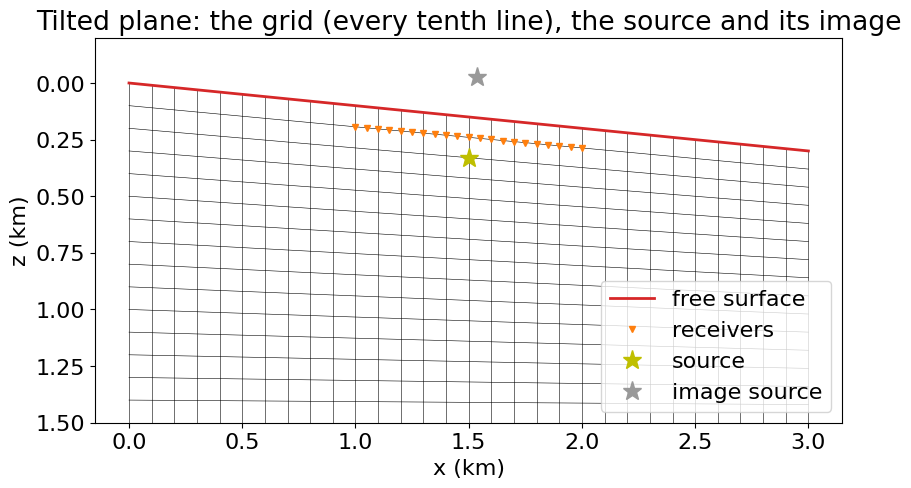

In [51]:
# NBVAL_IGNORE_OUTPUT
xp, zp = (c.data[:, above:]/1000 for c in plane.coordinates)
normal = np.array([slope, -1.])
image_source = plane_source[0] - 2*(normal @ plane_source[0])/(normal @ normal)*normal
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(xp[::10, :].T, zp[::10, :].T, 'k', lw=.4)
ax.plot(xp[:, ::10], zp[:, ::10], 'k', lw=.4)
ax.plot(xp[:, 0], zp[:, 0], 'C3', lw=2, label='free surface')
ax.plot(*(plane_receivers[::5]/1000).T, 'v', color='C1', ms=4, label='receivers')
ax.plot(*(plane_source/1000).T, 'y*', ms=14, label='source')
ax.plot(*(image_source/1000), '*', color='0.6', ms=14, label='image source')
ax.set_ylim(1.5, -.2)
ax.set_aspect('equal')
ax.set_xlabel('x (km)')
ax.set_ylabel('z (km)')
ax.legend(loc='lower right')
ax.set_title('Tilted plane: the grid (every tenth line), the source and its image')
plt.show()

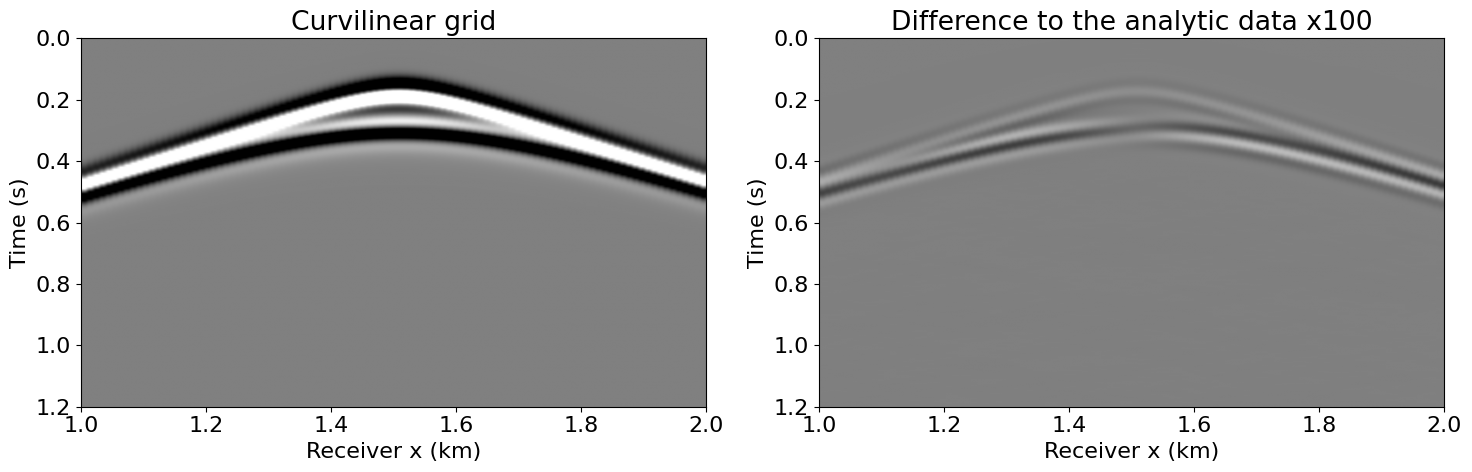

In [52]:
# NBVAL_IGNORE_OUTPUT
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
clip = np.abs(plane_analytic).max()/3
extent = [1., 2., tn, 0]
for ax, data, title in zip(axes, [plane_data, 100*(plane_data - plane_analytic)],
                           ['Curvilinear grid', 'Difference to the analytic data x100'],
                           strict=True):
    ax.imshow(data, aspect='auto', cmap='gray', vmin=-clip, vmax=clip, extent=extent)
    ax.set_xlabel('Receiver x (km)')
    ax.set_ylabel('Time (s)')
    ax.set_title(title)
plt.tight_layout()
plt.show()

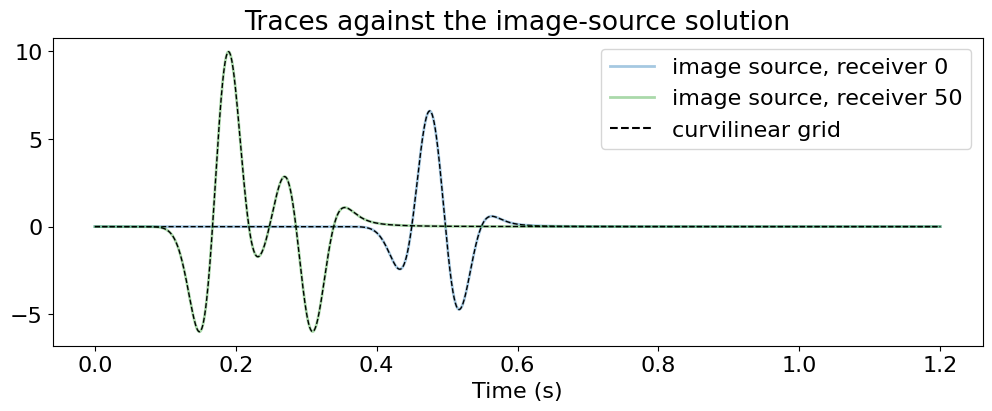

In [53]:
# NBVAL_IGNORE_OUTPUT
fig, ax = plt.subplots(figsize=(12, 4))
for index, color in [(0, 'C0'), (50, 'C2')]:
    ax.plot(plane_time, plane_analytic[:, index], color, lw=2, alpha=.4,
            label=f'image source, receiver {index}')
    ax.plot(plane_time, plane_data[:, index], 'k--', lw=1)
ax.plot([], [], 'k--', label='curvilinear grid')
ax.set_xlabel('Time (s)')
ax.set_title('Traces against the image-source solution')
ax.legend()
plt.show()

The difference, magnified a hundred times, is of the order of a thousandth of the data, at the 10 m spacing and time step of the hill.

In [54]:
assert misfit < 2e-3

### The same plane with a custom map

`TerrainFollowing` covers topography, but other geometries need other maps. A map is a subclass of `CurvilinearMap` that defines `forward`, the physical coordinates of computational points, which must be smooth slightly past the edges of the grid, where the finite differences of the map read it. The metric terms and the Jacobian are computed by finite differences of `forward`, and the computational coordinates of physical points, which place sparse functions, by Newton iterations on it, unless the map defines `inverse` in closed form. As an example, the plane can also be built by shearing the grid, shifting each column down by `slope*x` instead of stretching it, $z = \eta + 0.1\,\xi$:

In [55]:
class Shear(CurvilinearMap):

    def __init__(self, slope):
        super().__init__()
        self.slope = slope

    def forward(self, grid, computational):
        xi, eta = computational
        return xi, eta + self.slope*xi

    def inverse(self, grid, points):
        return np.stack([points[:, 0], points[:, 1] - self.slope*points[:, 0]],
                        axis=1)

In [56]:
# NBVAL_IGNORE_OUTPUT
shear_misfit = plane_misfit(Shear(slope), 10.)[0]
print(f'sheared plane: relative misfit {shear_misfit:.1e}')

Operator `Kernel` ran in 0.29 s


sheared plane: relative misfit 2.2e-03


In [57]:
assert shear_misfit < 3e-3

### A mesh of node coordinates

A grid is often given as the physical coordinates of its nodes, e.g. a mesh bent around a seabed that a surface cannot describe. `MeshMap` takes them and interpolates between them. Here the nodes of the double-precision hill grid of section 2 are shifted sideways by up to 40 m with depth, so that its columns bend; the Laplacian of the smooth field of section 2 is as accurate on it as on the hill grid.

In [58]:
# NBVAL_IGNORE_OUTPUT
# The nodes of the double-precision copy of the hill grid of section 2
x_nodes, z_nodes = (np.array(c.data) for c in check.coordinates)
x_bent = x_nodes + 40.*np.sin(np.pi*(z_nodes + 80.)/1580.)
bent = CurvilinearGrid(shape=grid.shape, extent=grid.extent, origin=grid.origin,
                       mapping=MeshMap((x_bent, z_nodes)), dtype=np.float64)
xb, zb = (c.data for c in bent.coordinates)
field_bent = Function(name='field_bent', grid=bent, space_order=8)
laplacian_bent = Function(name='laplacian_bent', grid=bent, space_order=8)
field_bent.data[:] = np.sin(k*xb)*np.cos(k*zb)
summary = Operator(Eq(laplacian_bent, field_bent.laplace)).apply()
error_bent = (laplacian_bent.data - (-2*k**2)*field_bent.data)/(2*k**2)
print(f'largest error on the bent mesh {np.abs(error_bent[inner]).max():.1e}')

Operator `Kernel` ran in 0.01 s


largest error on the bent mesh 2.4e-08


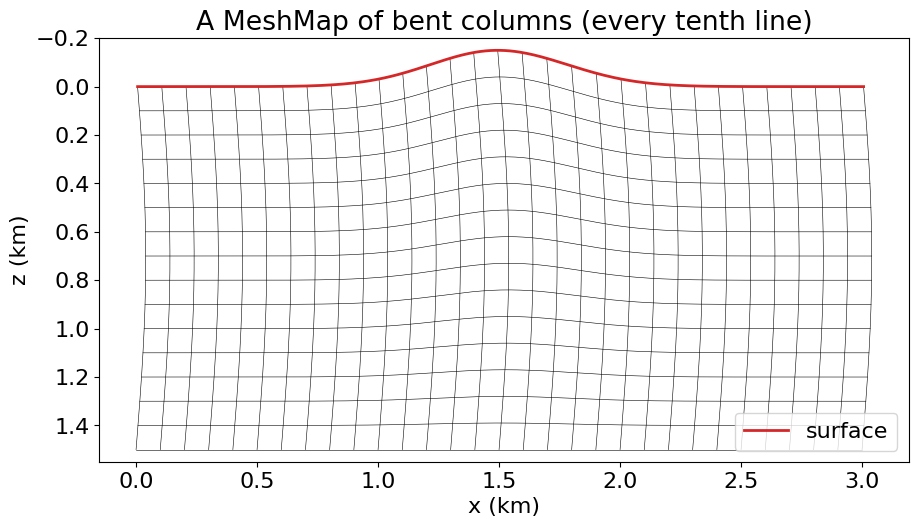

In [59]:
# NBVAL_IGNORE_OUTPUT
fig, ax = plt.subplots(figsize=(12, 5.5))
ax.plot(xb[::10, above:].T/1000, zb[::10, above:].T/1000, 'k', lw=.4)
ax.plot(xb[:, above::10]/1000, zb[:, above::10]/1000, 'k', lw=.4)
ax.plot(xb[:, above]/1000, zb[:, above]/1000, 'C3', lw=2, label='surface')
ax.set_ylim(1.55, -.2)
ax.set_aspect('equal')
ax.set_xlabel('x (km)')
ax.set_ylabel('z (km)')
ax.legend(loc='lower right')
ax.set_title('A MeshMap of bent columns (every tenth line)')
plt.show()

In [60]:
assert np.abs(error_bent[inner]).max() < 1e-6

## 10. Seismic models

The models of the seismic examples build the grid themselves. With `fs=True`, the grid extends `space_order` rows above the surface, into which the free surface of the solvers mirrors the fields, on a `Grid` as on a `CurvilinearGrid`. With a `surface` as well, `SeismicModel` builds a `CurvilinearGrid` with a `TerrainFollowing` map: the surface is given over the physical domain and continued flat across the absorbing layers, the parameters are continued into the rows above it, and the critical time step follows the smallest cell. `coordinates=` builds it from the node coordinates of the physical domain instead, and `mapping=` from any map. The acoustic and TTI solvers of the examples run on such a model unchanged.

In [61]:
# NBVAL_IGNORE_OUTPUT
x_model = np.linspace(0., 3000., 301)
model = SeismicModel(origin=(0., 0.), spacing=(10., 10.), shape=(301, 151),
                     space_order=8, vp=1.5, nbl=40, fs=True, bcs='damp',
                     surface=-elevation(x_model))
print(f'{type(model.grid).__name__}, shape {tuple(map(int, model.grid.shape))}, '
      f'vertical origin {float(model.grid.origin[-1]):.0f} m, '
      f'critical dt {model.critical_dt:.3f} ms')

Operator `initdamp` ran in 0.01 s


CurvilinearGrid, shape (381, 199), vertical origin -80 m, critical dt 3.001 ms


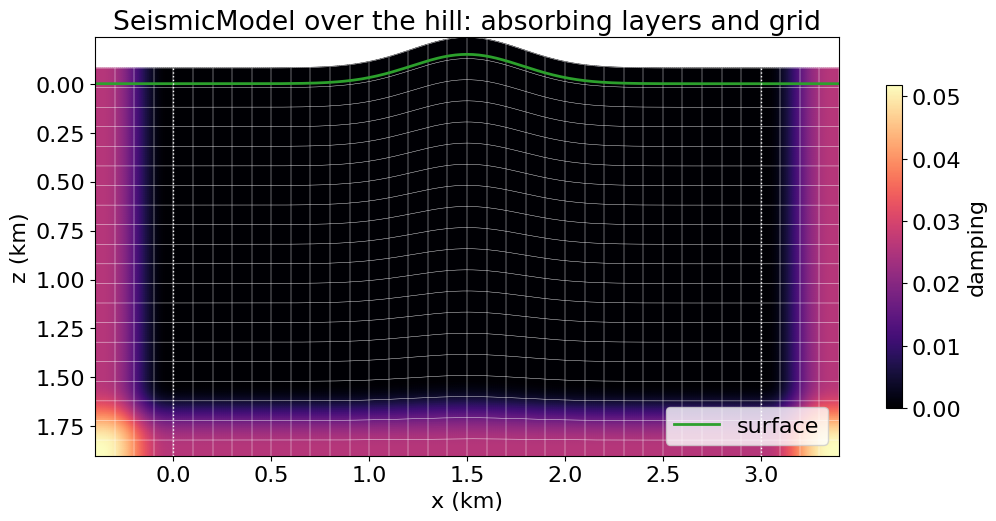

In [62]:
# NBVAL_IGNORE_OUTPUT
xm, zm = (c.data/1000 for c in model.grid.coordinates)
fig, ax = plt.subplots(figsize=(12, 6))
image = ax.pcolormesh(xm, zm, model.damp.data, cmap='magma', shading='gouraud')
ax.plot(xm[::10, :].T, zm[::10, :].T, 'w', lw=.3)
ax.plot(xm[:, ::10], zm[:, ::10], 'w', lw=.3)
top = model.mirror_rows
ax.plot(xm[:, top], zm[:, top], 'C2', lw=2, label='surface')
ax.axvline(0., color='w', lw=1, ls=':')
ax.axvline(3., color='w', lw=1, ls=':')
ax.invert_yaxis()
ax.set_aspect('equal')
ax.set_xlabel('x (km)')
ax.set_ylabel('z (km)')
ax.legend(loc='lower right')
ax.set_title('SeismicModel over the hill: absorbing layers and grid')
fig.colorbar(image, ax=ax, shrink=.7, label='damping')
plt.show()

Operator `Forward` ran in 0.07 s


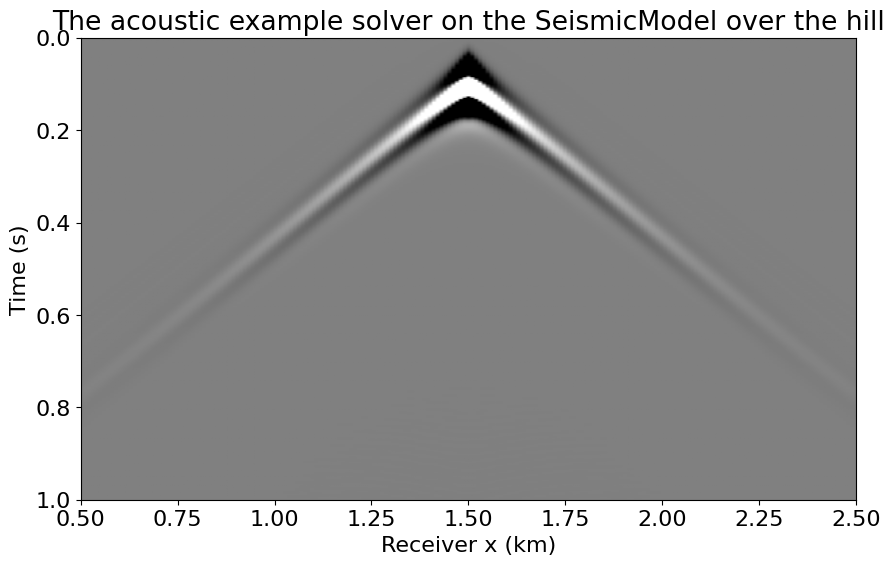

In [63]:
# NBVAL_IGNORE_OUTPUT
geometry = AcquisitionGeometry(model, receiver_positions, source_position, 0., 1000.,
                               f0=.010, src_type='Ricker')
record = AcousticWaveSolver(model, geometry, space_order=8).forward()[0]
fig, ax = plt.subplots(figsize=(10, 6))
clip = .05*np.abs(record.data).max()
ax.imshow(record.data, aspect='auto', cmap='gray', vmin=-clip, vmax=clip,
          extent=[receiver_x[0]/1000, receiver_x[-1]/1000, 1., 0])
ax.set_xlabel('Receiver x (km)')
ax.set_ylabel('Time (s)')
ax.set_title('The acoustic example solver on the SeismicModel over the hill')
plt.show()

## Going further

* The operators of this notebook run with MPI (`DEVITO_MPI=1 mpirun -n 4 python ...`): each rank builds the coordinates and metric terms of its own nodes and places the sparse points it holds. The cells that set data from NumPy arrays of the whole grid, e.g. the velocity or the mesh of section 9, then need the arrays of each rank instead. The free surface reads the rows below it up to $2s$, so a decomposition along the vertical `Dimension` needs ranks of at least $2s + 1$ rows; the free surface of the seismic examples checks it. The cells that read `.data` to plot or compare, e.g. the dot tests, see only the part held by their rank, and need it gathered first.
* The same grid works in 3D, with a surface $s(x, y)$ and `Dimension`s `x`, `y`, `z`.
* The docstrings of `CurvilinearGrid`, `TerrainFollowing`, `MeshMap`, `CurvilinearMap`, `devito.resample`, `Derivative` and the module `devito.finite_differences.curvilinear` describe every option.